# 01 · Exploratory Data Analysis — SECOM

**FabGuard** · Munib Ahmed & Sindi Banda · CS 533 Fall 2026

Questions from the proposal:
1. How imbalanced are the classes, and does the failure rate change over time?
2. What do the missing values look like, and how many sensors are constant or redundant?
3. How are sensors distributed, and do they need scaling?
4. Do passing and failing samples differ on any individual sensor?
5. Does PCA show any separation between the classes?

**Leakage rule.** Anything that could inform a modeling decision (missingness cutoff, feature
statistics, correlations, PCA) is computed on the **training split only**. Only the labels and
timestamps, which inform no preprocessing, are summarized on the full dataset.
Every figure is also saved to `Reports/Figures/eda_*.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from scipy import stats
from sklearn.decomposition import PCA

from FabGuard.data import load_secom, split_data
from FabGuard.plotting import (AQUA, BLUE, CLASS_COLORS, CLASS_NAMES, GRID, MUTED, ORANGE,
                               savefig, set_style)
from FabGuard.preprocessing import CorrelationFilter, build_preprocessor

set_style()
pd.set_option("display.precision", 3)

X, y, timestamps = load_secom()
X_train, X_test, y_train, y_test = split_data(X, y)
print(f"Full data: {X.shape[0]} samples x {X.shape[1]} sensors")
print(f"Train: {len(y_train)} ({y_train.sum()} failures)   Test: {len(y_test)} ({y_test.sum()} failures)")

Full data: 1567 samples x 590 sensors
Train: 1253 (83 failures)   Test: 314 (21 failures)


## 1. Class balance

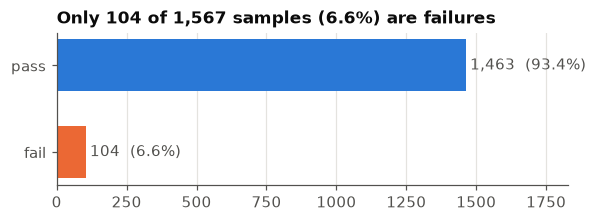

Always predicting 'pass' gives 93.4% accuracy while catching 0 failures.


In [2]:
counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6, 1.8))
ax.barh([CLASS_NAMES[c] for c in counts.index], counts.values,
        color=[CLASS_COLORS[c] for c in counts.index], height=0.6)
for i, v in enumerate(counts.values):
    ax.text(v + 15, i, f"{v:,}  ({v / len(y):.1%})", va="center", color=MUTED)
ax.set_xlim(0, counts.max() * 1.25)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Only 104 of 1,567 samples (6.6%) are failures")
savefig(fig, "eda_class_balance")
plt.show()

print(f"Always predicting 'pass' gives {1 - y.mean():.1%} accuracy while catching 0 failures.")

A classifier that always says *pass* is 93.4% accurate, which is why we report recall,
precision, F1, ROC-AUC and PR-AUC instead of accuracy (the Dummy baseline demonstrates this).

## 2. Failure rate over time

Data spans 2008-07-19 to 2008-10-17


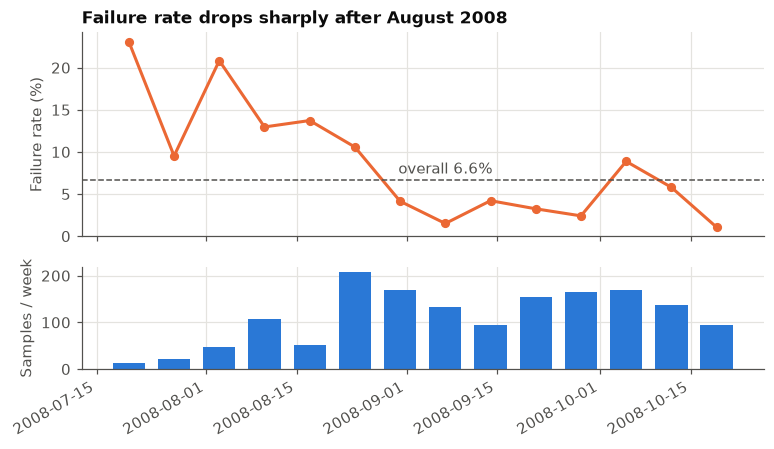

Failure rate before Sep 1: 10.5% (n=618),  after: 4.1% (n=949)


In [3]:
weekly = (pd.DataFrame({"fail": y.values}, index=timestamps.values)
          .resample("W").fail.agg(["mean", "count", "sum"]))
print(f"Data spans {timestamps.min():%Y-%m-%d} to {timestamps.max():%Y-%m-%d}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1]})
ax1.plot(weekly.index, weekly["mean"] * 100, color=ORANGE, marker="o", markersize=5)
ax1.axhline(y.mean() * 100, color=MUTED, linestyle="--", linewidth=1)
ax1.text(weekly.index[7], y.mean() * 100 + 0.8, "overall 6.6%", color=MUTED, ha="center")
ax1.set_ylabel("Failure rate (%)")
ax1.set_title("Failure rate drops sharply after August 2008")
ax2.bar(weekly.index, weekly["count"], width=5, color=BLUE)
ax2.set_ylabel("Samples / week")
fig.autofmt_xdate()
savefig(fig, "eda_failure_rate_over_time")
plt.show()

aug = timestamps < "2008-09-01"
print(f"Failure rate before Sep 1: {y[aug].mean():.1%} (n={aug.sum()}),  after: {y[~aug].mean():.1%} (n={(~aug).sum()})")

The process is **not stationary**: weekly failure rates of 10–23% in July–August fall to
1–4% in September. A random stratified split mixes both periods into train and test, which is
what the proposal specifies and what prior SECOM papers do. A model deployed in a fab, though,
would be trained on the past and applied to the future, so a **chronological split is a
useful robustness check** for the comparison phase.

## 3. Missing values (training split)

In [4]:
missing = X_train.isna().mean()
print(f"Overall missing: {X_train.isna().values.mean():.2%} of cells")
print(f"Every sample has at least one missing sensor: {X_train.isna().any(axis=1).all()}")
print(f"Sensors with any missing: {(missing > 0).sum()} / {len(missing)}")
for cut in [0.05, 0.2, 0.5, 0.8]:
    print(f"  > {cut:.0%} missing: {(missing > cut).sum()}")
print(f"Distinct missingness patterns among sensors: {X_train.loc[:, missing > 0].isna().T.drop_duplicates().shape[0]}")

Overall missing: 4.58% of cells
Every sample has at least one missing sensor: True
Sensors with any missing: 506 / 590
  > 5% missing: 52
  > 20% missing: 32
  > 50% missing: 24
  > 80% missing: 8


Distinct missingness patterns among sensors: 34


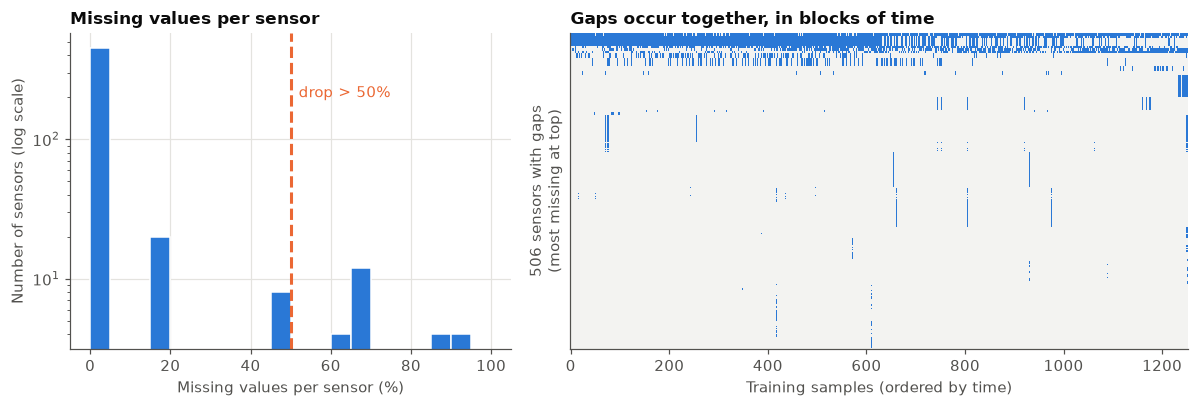

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1, 1.4]})

ax1.hist(missing[missing > 0] * 100, bins=np.arange(0, 101, 5), color=BLUE, edgecolor="white")
ax1.axvline(50, color=ORANGE, linestyle="--")
ax1.text(52, 200, "drop > 50%", color=ORANGE)
ax1.set_xlabel("Missing values per sensor (%)")
ax1.set_ylabel("Number of sensors (log scale)")
ax1.set_yscale("log")
ax1.set_title("Missing values per sensor")

cols = missing[missing > 0].sort_values(ascending=False).index
order = timestamps.loc[X_train.index].sort_values().index
ax2.imshow(X_train.loc[order, cols].isna().T.values, aspect="auto", interpolation="nearest",
           cmap=ListedColormap(["#f3f3f1", BLUE]))
ax2.set_xlabel("Training samples (ordered by time)")
ax2.set_ylabel(f"{len(cols)} sensors with gaps\n(most missing at top)")
ax2.set_title("Gaps occur together, in blocks of time")
ax2.grid(False)
ax2.set_yticks([])
fig.tight_layout()
savefig(fig, "eda_missingness")
plt.show()

In [6]:
# Is missingness itself informative about failure?
rows = []
for c in missing[(missing > 0.02) & (missing < 0.98)].index:
    gap = X_train[c].isna()
    rows.append({"sensor": c, "missing": missing[c],
                 "fail_rate_if_missing": y_train[gap].mean(),
                 "fail_rate_if_present": y_train[~gap].mean()})
miss_info = pd.DataFrame(rows)
miss_info["difference"] = miss_info.fail_rate_if_missing - miss_info.fail_rate_if_present
print("Largest differences in failure rate between rows with and without a gap:")
miss_info.reindex(miss_info.difference.abs().sort_values(ascending=False).index).head(6)

Largest differences in failure rate between rows with and without a gap:


,sensor,missing,fail_rate_if_missing,fail_rate_if_present,difference
30,sensor_496,0.03,0.026,0.067,-0.041
12,sensor_224,0.03,0.026,0.067,-0.041
31,sensor_497,0.03,0.026,0.067,-0.041
3,sensor_089,0.03,0.026,0.067,-0.041
4,sensor_090,0.03,0.026,0.067,-0.041
24,sensor_363,0.03,0.026,0.067,-0.041


- Missing values are concentrated: 24 sensors exceed the 50% cutoff in the training split,
  while all but 52 are under 5% missing. The heatmap shows sensors dropping out **together and in time blocks**, consistent
  with whole instruments or measurement steps being offline, not random gaps.
- Whether a sensor is missing barely changes the failure rate (at most ~4 percentage points),
  so a missing-indicator feature is unlikely to help. Median imputation is a reasonable default.

## 4. Constant sensors and sensor scales (training split)

Constant sensors (single value): 116 / 590
Std. deviation of non-constant sensors ranges from 1.0e-04 to 6.5e+03


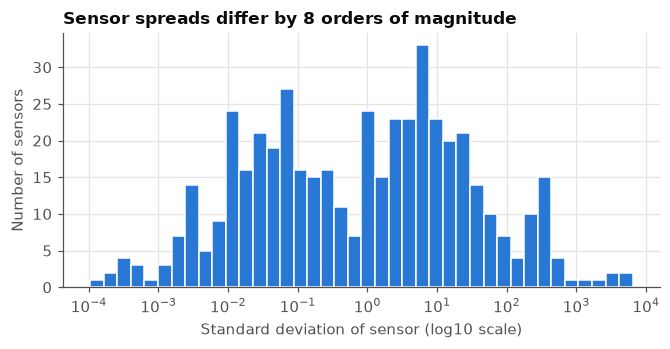

In [7]:
nunique = X_train.nunique()
constant = (nunique <= 1).sum()
std = X_train.std()
print(f"Constant sensors (single value): {constant} / {X_train.shape[1]}")
print(f"Std. deviation of non-constant sensors ranges from {std[std > 0].min():.1e} to {std.max():.1e}")

fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(np.log10(std[std > 0]), bins=40, color=BLUE, edgecolor="white")
ax.set_xlabel("Standard deviation of sensor (log10 scale)")
ax.set_ylabel("Number of sensors")
ax.set_xticks(range(-4, 5))
ax.set_xticklabels([f"$10^{{{k}}}$" for k in range(-4, 5)])
ax.set_title("Sensor spreads differ by 8 orders of magnitude")
savefig(fig, "eda_sensor_scales")
plt.show()

116 sensors never change and carry no information; they are removed by the zero-variance step.
The remaining sensors are measured on wildly different scales (standard deviations from
0.0001 to over 6,000), so **standardization is required** for Logistic Regression and any
distance-based method; tree models (XGBoost) are unaffected.

## 5. Do passing and failing samples differ? (training split)

In [8]:
usable = X_train.columns[(nunique > 1) & (missing <= 0.5)]
pvals, corrs = {}, {}
for c in usable:
    pvals[c] = stats.mannwhitneyu(X_train.loc[y_train == 0, c].dropna(),
                                  X_train.loc[y_train == 1, c].dropna()).pvalue
    filled = X_train[c].fillna(X_train[c].median())
    corrs[c] = np.corrcoef(filled, y_train)[0, 1]
pvals, corrs = pd.Series(pvals).fillna(1.0), pd.Series(corrs).fillna(0.0)
qvals = pd.Series(stats.false_discovery_control(pvals), index=pvals.index)

print(f"Sensors tested: {len(pvals)}")
print(f"p < 0.05: {(pvals < 0.05).sum()}  (about {0.05 * len(pvals):.0f} expected by chance alone)")
print(f"Significant after Benjamini-Hochberg FDR correction (q < 0.05): {(qvals < 0.05).sum()}")
print(f"Largest |correlation| with failure: {corrs.abs().max():.3f};  sensors with |r| > 0.1: {(corrs.abs() > 0.1).sum()}")

Sensors tested: 450
p < 0.05: 78  (about 22 expected by chance alone)
Significant after Benjamini-Hochberg FDR correction (q < 0.05): 15
Largest |correlation| with failure: 0.172;  sensors with |r| > 0.1: 7


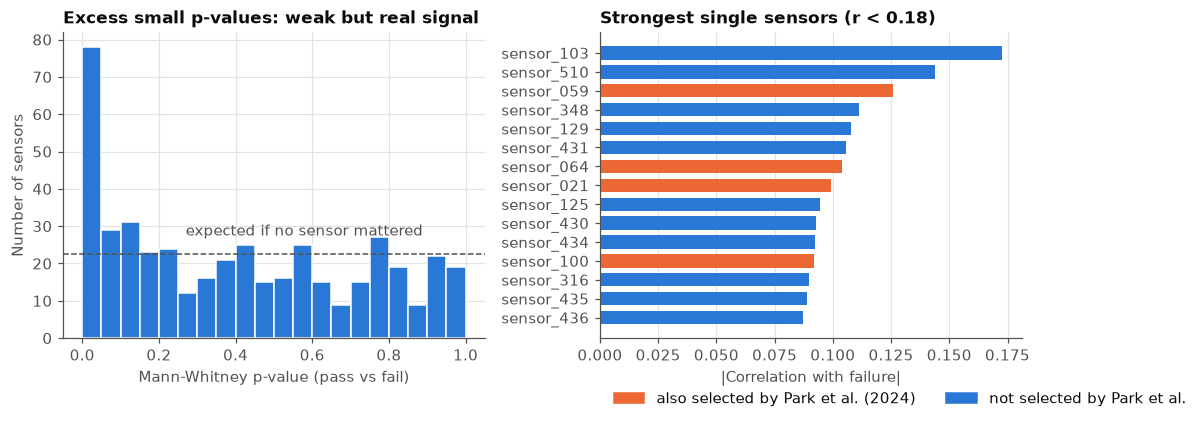

Correlation in our training split for Park et al.'s 12 selected sensors:
sensor_021    0.099
sensor_059    0.126
sensor_064    0.104
sensor_100    0.092
sensor_122   -0.085
sensor_330      NaN
sensor_407    0.032
sensor_408   -0.026
sensor_411    0.062
sensor_412    0.015
sensor_413    0.009
sensor_486    0.022


In [9]:
park = [f"sensor_{i:03d}" for i in [21, 59, 64, 100, 122, 330, 407, 408, 411, 412, 413, 486]]
top = corrs.abs().sort_values(ascending=False).head(15)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.hist(pvals, bins=np.linspace(0, 1, 21), color=BLUE, edgecolor="white")
ax1.axhline(len(pvals) / 20, color=MUTED, linestyle="--", linewidth=1)
ax1.text(0.27, len(pvals) / 20 + 5, "expected if no sensor mattered", color=MUTED)
ax1.set_xlabel("Mann-Whitney p-value (pass vs fail)")
ax1.set_ylabel("Number of sensors")
ax1.set_title("Excess small p-values: weak but real signal")

colors = [ORANGE if s in park else BLUE for s in top.index]
ax2.barh(top.index[::-1], top.values[::-1], color=colors[::-1], height=0.7)
ax2.set_xlabel("|Correlation with failure|")
ax2.set_title("Strongest single sensors (r < 0.18)")
ax2.grid(axis="y", visible=False)
ax2.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=ORANGE), plt.Rectangle((0, 0), 1, 1, color=BLUE)],
           labels=["also selected by Park et al. (2024)", "not selected by Park et al."],
           loc="upper left", bbox_to_anchor=(0, -0.13), ncol=2)
fig.tight_layout()
savefig(fig, "eda_univariate_signal")
plt.show()

print("Correlation in our training split for Park et al.'s 12 selected sensors:")
print(corrs.reindex(park).round(3).to_string())

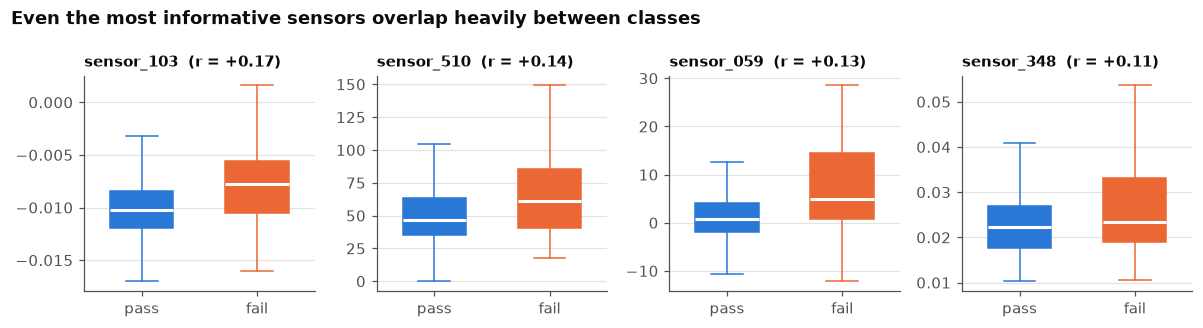

In [10]:
best = corrs.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=False)
for ax, c in zip(axes, best):
    data = [X_train.loc[y_train == k, c].dropna() for k in (0, 1)]
    parts = ax.boxplot(data, tick_labels=["pass", "fail"], widths=0.55, patch_artist=True,
                       showfliers=False, medianprops={"color": "white", "linewidth": 2})
    for patch, k in zip(parts["boxes"], (0, 1)):
        patch.set(facecolor=CLASS_COLORS[k], edgecolor=CLASS_COLORS[k])
    for el in ("whiskers", "caps"):
        for line, k in zip(parts[el], (0, 0, 1, 1)):
            line.set_color(CLASS_COLORS[k])
    ax.set_title(f"{c}  (r = {corrs[c]:+.2f})", fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Even the most informative sensors overlap heavily between classes",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
savefig(fig, "eda_top_sensors_by_class")
plt.show()

- 78 sensors have p < 0.05 versus ~22 expected by chance, and 15 survive FDR correction:
  the sensors do carry **some** information about failure.
- But every effect is small: no sensor correlates with failure above 0.18, and the
  class distributions of the best sensors overlap almost completely. Failures are not
  explained by any single sensor, which caps what simple models can reach.
- Park et al. (2024) selected 12 sensors with |r| > 0.1 on *their* split. On ours, only a few
  of them still clear 0.1, most are near zero, and sensor_330 is constant in our training split.
  **Correlation-based selection is unstable across splits** (their sensor numbering may also be
  1-based; either way the overlap is small). This supports tuning feature selection inside cross-validation, as our
  pipeline does, rather than fixing a sensor list once.

## 6. Redundant sensors (training split)

Sensors after missing/constant filtering: 450
Sensor pairs with |r| > 0.8: 608;  > 0.95: 277


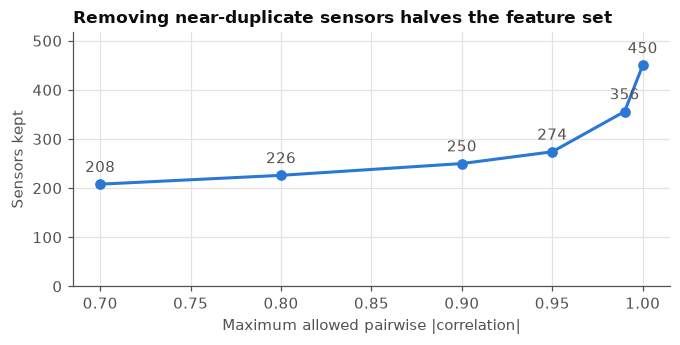

In [11]:
base = build_preprocessor(scale=False, n_features=None).fit(X_train)
Z = pd.DataFrame(base.transform(X_train), columns=base.get_feature_names_out())
abs_corr = np.abs(np.corrcoef(Z.values, rowvar=False))
pairs = abs_corr[np.triu_indices_from(abs_corr, k=1)]
print(f"Sensors after missing/constant filtering: {Z.shape[1]}")
print(f"Sensor pairs with |r| > 0.8: {(pairs > 0.8).sum():,};  > 0.95: {(pairs > 0.95).sum():,}")

thresholds = [0.7, 0.8, 0.9, 0.95, 0.99, 1.0]
kept = [CorrelationFilter(max_corr=t).fit(Z).support_.sum() for t in thresholds]

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(thresholds, kept, color=BLUE, marker="o", markersize=6)
for t, k in zip(thresholds, kept):
    ax.annotate(f"{k}", (t, k), textcoords="offset points", xytext=(0, 8), ha="center", color=MUTED)
ax.set_xlabel("Maximum allowed pairwise |correlation|")
ax.set_ylabel("Sensors kept")
ax.set_ylim(0, Z.shape[1] * 1.15)
ax.set_title("Removing near-duplicate sensors halves the feature set")
savefig(fig, "eda_redundancy")
plt.show()

Many sensors are near-copies of each other: at a 0.8 cutoff, about half can be dropped
without losing a distinct signal. This is the correlation filter tuned inside the Logistic
Regression grid (Munirathinam & Ramadoss, 2016), and it was selected by cross-validation.

## 7. PCA (fit on the training split after preprocessing)

In [12]:
prep = build_preprocessor(n_features=None).fit(X_train)
Zs = prep.transform(X_train)
pca = PCA(random_state=0).fit(Zs)
cum = np.cumsum(pca.explained_variance_ratio_)
for v in (0.5, 0.8, 0.9):
    print(f"Components for {v:.0%} of variance: {np.searchsorted(cum, v) + 1}")
pcs = pca.transform(Zs)[:, :3]
t_train = timestamps.loc[X_train.index]
for i in range(3):
    print(f"PC{i + 1}: {pca.explained_variance_ratio_[i]:.1%} of variance, "
          f"corr with time = {np.corrcoef(pcs[:, i], t_train.astype('int64'))[0, 1]:+.2f}")

Components for 50% of variance: 31
Components for 80% of variance: 86
Components for 90% of variance: 127
PC1: 6.0% of variance, corr with time = +0.03
PC2: 3.8% of variance, corr with time = -0.55
PC3: 3.0% of variance, corr with time = -0.31


51 of 1253 points lie outside the plotted range


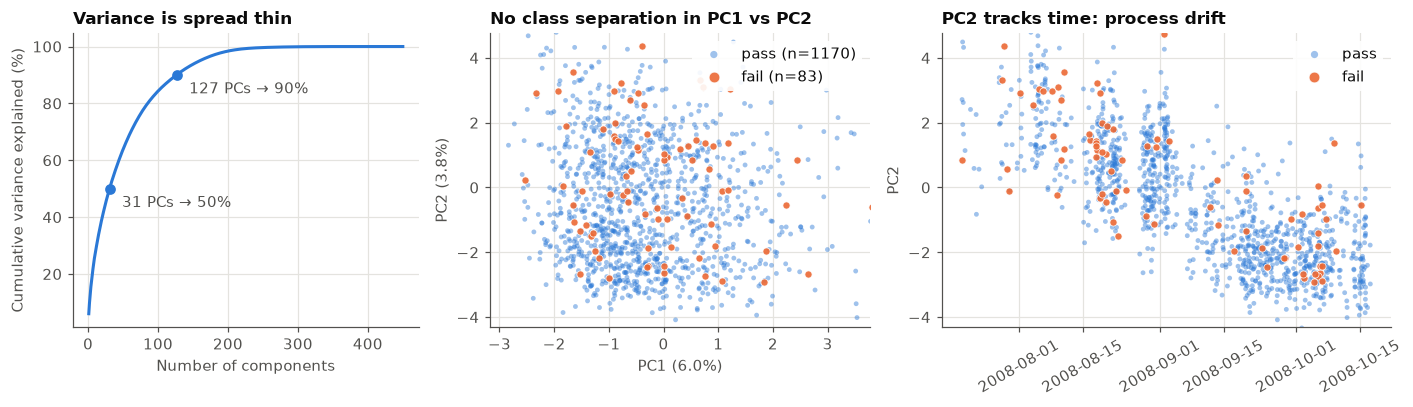

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 1.1, 1.3]})

ax = axes[0]
ax.plot(np.arange(1, len(cum) + 1), cum * 100, color=BLUE)
for v in (0.5, 0.9):
    n = np.searchsorted(cum, v) + 1
    ax.plot(n, v * 100, "o", color=BLUE, markersize=6)
    ax.annotate(f"{n} PCs → {v:.0%}", (n, v * 100), textcoords="offset points", xytext=(8, -12), color=MUTED)
ax.set_xlabel("Number of components")
ax.set_ylabel("Cumulative variance explained (%)")
ax.set_title("Variance is spread thin")

ax = axes[1]
for k in (0, 1):
    m = (y_train == k).values
    ax.scatter(pcs[m, 0], pcs[m, 1], s=10 if k == 0 else 22, alpha=0.45 if k == 0 else 0.9,
               color=CLASS_COLORS[k], edgecolor="white" if k == 1 else "none", linewidth=0.5,
               label=f"{CLASS_NAMES[k]} (n={m.sum()})", zorder=2 + k)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
def central(v, pct=2):
    lo, hi = np.percentile(v, [pct, 100 - pct])
    pad = (hi - lo) * 0.15
    return lo - pad, hi + pad
xlim, ylim = central(pcs[:, 0]), central(pcs[:, 1], pct=4)
n_out = ((pcs[:, 0] < xlim[0]) | (pcs[:, 0] > xlim[1]) | (pcs[:, 1] < ylim[0]) | (pcs[:, 1] > ylim[1])).sum()
print(f"{n_out} of {len(pcs)} points lie outside the plotted range")
ax.set_xlim(xlim); ax.set_ylim(ylim)
ax.set_title("No class separation in PC1 vs PC2")
ax.legend(loc="upper right", markerscale=1.5, frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)

ax = axes[2]
for k in (0, 1):
    m = (y_train == k).values
    ax.scatter(t_train[m], pcs[m, 1], s=10 if k == 0 else 22, alpha=0.45 if k == 0 else 0.9,
               color=CLASS_COLORS[k], edgecolor="white" if k == 1 else "none", linewidth=0.5,
               label=CLASS_NAMES[k], zorder=2 + k)
ax.set_ylim(ylim)
ax.set_ylabel("PC2")
ax.tick_params(axis="x", labelrotation=30)
ax.set_title("PC2 tracks time: process drift")
ax.legend(loc="upper right", markerscale=1.5, frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
fig.tight_layout()
savefig(fig, "eda_pca")
plt.show()

- The first two components explain under 10% of the variance, and it takes over 100
  components to reach 90%: there is no compact low-dimensional structure.
- Failures are scattered through the pass cloud with no visible separation (axes are clipped
  to the central ~96% of points; the printed count of outliers lies outside).
- The second component is strongly correlated with time, so the largest shared variation in
  the sensors is **process drift**, not pass/fail. This matches the drift in the failure rate
  (Section 2) and is another reason to check a chronological split.

## Takeaways for modeling

| Finding | Consequence for the pipeline |
|---|---|
| 6.6% failures; always-pass is 93.4% accurate | Dummy baseline; report recall, PR-AUC, GM, not accuracy |
| 28 sensors > 50% missing; gaps occur in blocks; missingness not predictive | Drop > 50% missing, median-impute the rest (fit on train) |
| 116 constant sensors | Zero-variance filter |
| Sensor scales span 8 orders of magnitude | Standardize for Logistic Regression / distance methods |
| Weak univariate signal (max \|r\| = 0.17, 15 FDR-significant sensors) | Expect modest performance; regularize; tune feature selection in CV |
| Half the sensors are near-duplicates | Correlation filter (selected by CV for Logistic Regression) |
| No separation in PCA; PC2 tracks time | Linear projection won't separate classes; check a time-based split |
| Failure rate drifts from ~15% (Aug) to ~3% (Sep) | Add a chronological-split robustness check in the comparison phase |